# import libraries

In [71]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pylab as plt
import sqlite3

## 1, import database / data 

In [72]:
conn = sqlite3.connect("customer.db")

sql_query="""
        select name 
        from sqlite_master
        where type = 'table'
"""

tables=pd.read_sql(sql_query,conn)

# create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"select * from {table_name}",conn)
    globals()[f"df_{table_name}"] = df
    print(f"created dataframe: df_{table_name}")

conn.close()

created dataframe: df_db_customer
created dataframe: df_db_subscription
created dataframe: df_db_support


In [73]:
# print table names and colum names

conn = sqlite3.connect("customer.db")


for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    
    # get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query,conn)
    print("Columns:")
    print(columns['name'].tolist())
    

conn.close()
# this funcation only show the columns and : like table name 
# table name: db_subscription
# table name : db_support


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


# data cleaning 

In [74]:
 df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [75]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


In [76]:
# a ,rename cloumn-
# b,drop column for insterts and pincode 
# c , change dob ka data type 
# d ,data standardization
# e , country me missing value fix 


In [77]:
# rename -columns for name
df_db_customer.rename(columns={'name': "customer_name"})
df_db_customer=df_db_customer.rename(columns={'name': "customer_name"})

In [78]:
df_db_customer

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
5,0013-MHZWF,durga,None,Delhi,Women,1988-12-10 00:00:00,None,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,None,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,None,None
8,0015-UOCOJ,maya,None,Kathmandu,Women,1985-07-07 00:00:00,None,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,None,None


In [79]:

# b,drop column for insterts and pincode
df_db_customer.drop(df_db_customer.columns[-2:],axis=1)
df_db_customer.drop(columns=['interests','pincode'],inplace=True)

In [80]:
# c , change dob ka data type
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerid     21 non-null     object
 1   customer_name  21 non-null     object
 2   country        18 non-null     object
 3   state          21 non-null     object
 4   gender         21 non-null     object
 5   dob            21 non-null     object
dtypes: object(6)
memory usage: 1.1+ KB


In [81]:
pd.to_datetime(df_db_customer['dob'])
df_db_customer['dob']=pd.to_datetime(df_db_customer['dob'])

In [82]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     object        
 1   customer_name  21 non-null     object        
 2   country        18 non-null     object        
 3   state          21 non-null     object        
 4   gender         21 non-null     object        
 5   dob            21 non-null     datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 1.1+ KB


In [83]:
# d ,data standardization
df_db_customer['gender'].unique()
df_db_customer['gender'].replace({'Men' : 'Male','Women' : 'Female'})
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male','Women' : 'Female'})

In [84]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05
5,0013-MHZWF,durga,None,Delhi,Female,1988-12-10
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14
8,0015-UOCOJ,maya,None,Kathmandu,Female,1985-07-07
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29


In [85]:
#  e , country me missing value fix 
df_db_customer[df_db_customer['country'].isna()]
df_db_customer['country']

0     India
1     India
2     India
3     India
4     India
5      None
6     India
7     India
8      None
9     Nepal
10    India
11    India
12     None
13    India
14    India
15    India
16    India
17    India
18    India
19    India
20    India
Name: country, dtype: object

In [86]:
df_db_customer[['country','state']]

# country abd state - unique value pair
maping=df_db_customer.dropna(subset=['country']).set_index("state")['country'].to_dict()

df_db_customer['country'].fillna(df_db_customer['state'].map(maping))

df_db_customer['country']=df_db_customer['country'].fillna(df_db_customer['state'].map(maping))

In [87]:
#  e , country me missing value fix 
df_db_customer['country'].isna().sum()

np.int64(0)

In [88]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [89]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      object 
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.9+ KB


In [90]:
date_col=['subscription_start_date','renewal_date','cancellation_date']

df_db_subscription[date_col]=df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     object        
 1   subscription_start_date  21 non-null     datetime64[ns]
 2   subscription_type        21 non-null     object        
 3   renewal_date             21 non-null     datetime64[ns]
 4   plan_type                21 non-null     object        
 5   contract_type            21 non-null     object        
 6   cancellation_date        6 non-null      datetime64[ns]
 7   cancellation_reason      6 non-null      object        
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.9+ KB


In [91]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      object
 1   complaint_date  9 non-null      object
 2   escalations     9 non-null      object
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      object
dtypes: int64(1), object(5)
memory usage: 564.0+ bytes


In [92]:
df_db_support.drop(columns=['col_1','comment'],inplace=True)

In [93]:
df_db_support['complaint_date']=pd.to_datetime(df_db_support['complaint_date'])

# 2 Feature Engineering and data analysis

In [94]:
 df_db_subscription['churm_flag'] =np.where(df_db_subscription['cancellation_date'].notna(), 1,0)

#### create a new columna using existing col = name(churm_flag)

In [95]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churm_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [96]:
# fix sport_table and marge
df=(df_db_subscription
    .merge(df_db_customer,on ='customerid', how ='left')
    .merge(df_db_support,on ='customerid', how ='left'))

In [97]:
df_db_subscription.shape

(21, 12)

In [98]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [99]:
df_db_support['complaint_count']=df_db_support.groupby('customerid')['customerid'].transform('count')

In [100]:
df_db_support=df_db_support.sort_values('complaint_count').drop_duplicates('customerid',keep = 'last')

In [101]:
# merge df
df=(df_db_subscription
    .merge(df_db_customer,on ='customerid', how ='left')
    .merge(df_db_support,on ='customerid', how ='left'))

In [102]:
df.to_csv("new_complect_data_set_using.csv")


## Data Analysis

In [103]:
# churm rate

In [104]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churm_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [105]:
churn_rate = df['churm_flag'].mean()*100
print("churm Rate =",round(churn_rate,2),"%")

churm Rate = 28.57 %


In [106]:
# 2 retenion rate

retention_rate = 100 - churn_rate
print("retenion Rate =",round(retention_rate,2),"%")

retenion Rate = 71.43 %


In [107]:
# churn by plan type
churn_by_plan = (df.groupby('plan_type')['churm_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)
# mixmum churn rate are (basice) for leaving 60% people lave ask


  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [108]:
# 4 churn by state + sum(revenue) & count by user 
# 4 b churn by subscription type + sum(revenue) & count by user

In [109]:
# 5 ARPU - avg revanve per user 
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churm_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [110]:
ARPU = df['monthly_charges'].mean()
print('ARPU',round(ARPU,2))

ARPU 18.85


In [111]:
# calculate customer age

In [112]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churm_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='object')

In [113]:
# 6  avg custumer tenure 
# count of days user has userd our servise : cancellation date current date
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)
avg_tenure = df['tenure_days'].mean()
print("avg_tenure (data)",round(avg_tenure),0)


avg_tenure (data) 1582 0


In [114]:
# 7 reveenue at risk  - revenue lost for churn user 
reveenue_at_risk = df.loc[df['churm_flag'] == 1,'monthly_charges'].sum()
print("reveenue at risk(rs 'k') =",reveenue_at_risk)

reveenue at risk(rs 'k') = 73.94


In [115]:
# 8 Escation rate 
#escalations_rate =(df['escalations'] == 'Y').mean()*100
print('escalations_rate',round(escalations_rate,2),'%')

escalations_rate 19.05 %


In [116]:
# 9 avg complatint par user 
avg_complet=df['complaint_count'].sum() / df['customerid'].nunique()
print('avg_complet_paruser',round(avg_complet,2))

avg_complet_paruser 0.43


In [117]:
# 10 correlation
df['escalations'] = np.where(df['escalations'] == 'Y',1,0)
corr_df =df[['escalations','churm_flag']].dropna()
correlation = corr_df['escalations'].corr(df['churm_flag'])
print('corretation for escalation vs churn_flag',round(correlation,2))

corretation for escalation vs churn_flag 0.77


# DATA Visualization using matplotib

In [118]:
df_n = df.copy()

In [119]:

df_n.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churm_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days'],
      dtype='object')

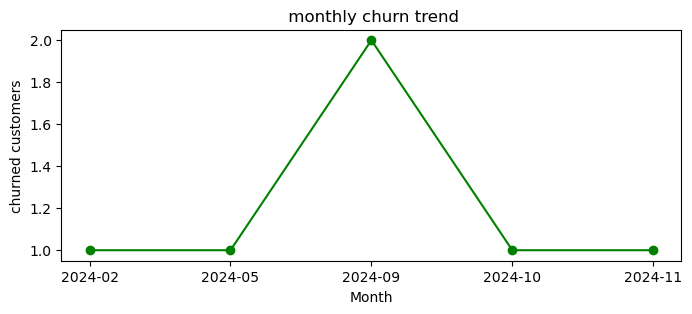

In [125]:
# Monthil churn Trend (time base accoding
df_n['cancellation_date'] = df_n['cancellation_date'].dt.to_period('M')

churn_trend=df_n[df_n['churm_flag'] == 1].groupby('cancellation_date').size()
plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str),churn_trend.values,color='green',marker='o')
plt.title(" monthly churn trend")
plt.xlabel('Month')
plt.ylabel('churned customers')
plt.show()

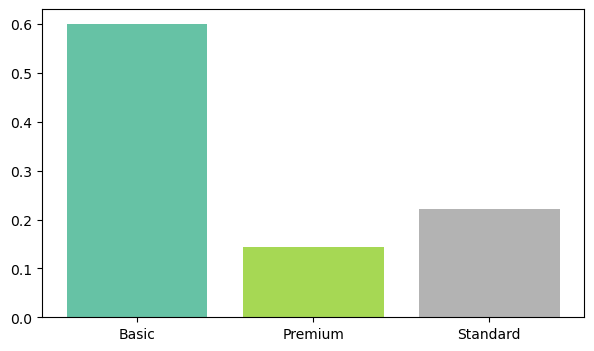

In [121]:
# 2 churn by plan type 
churn_plan = df_n.groupby('plan_type')['churm_flag'].mean()

colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan)))
plt.figure(figsize=(7,4))
plt.bar(churn_plan.index,churn_plan.values, color =colors)
plt.show()

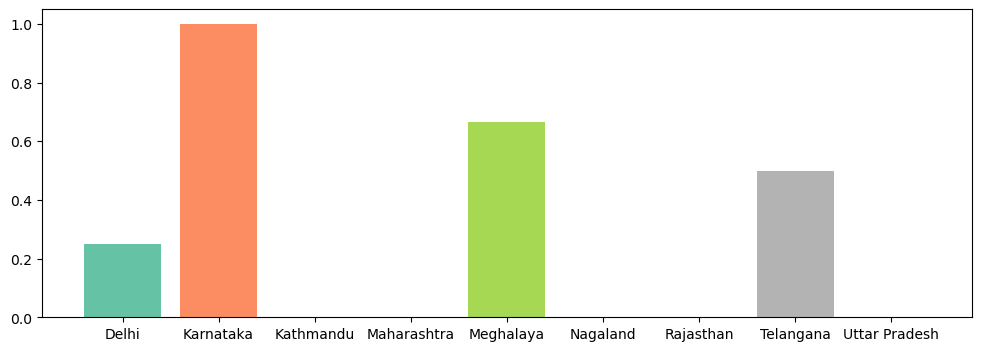

In [122]:
# churn by states
churn_plan = df_n.groupby('state')['churm_flag'].mean()

colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan)))
plt.figure(figsize=(12,4))
plt.bar(churn_plan.index,churn_plan.values, color =colors)
plt.show()

# DATA Visualization using seaborn

In [133]:
# encoding - covert str to numarical so that we can find corr between feature 
df_n.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churm_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days'],
      dtype='object')

In [145]:
df_encod=df_n[['plan_type','contract_type','churn_score','churm_flag','escalations']]

categorical_col =['plan_type','contract_type']
for col in categorical_col:
    df_encod[col]=df_encod[col].astype('category').cat.codes


C:\Users\text\AppData\Local\Temp\ipykernel_24052\2830853645.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_encod[col]=df_encod[col].astype('category').cat.codes
C:\Users\text\AppData\Local\Temp\ipykernel_24052\2830853645.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_encod[col]=df_encod[col].astype('category').cat.codes


<Axes: >

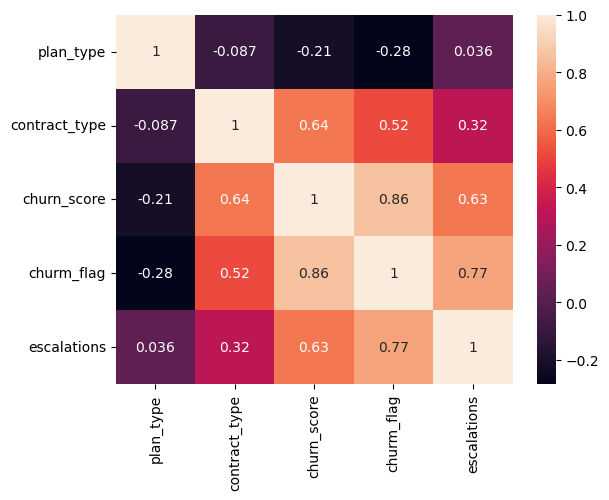

In [146]:
# Heatmape ( correlation matrix)
sns.heatmap(df_encod.corr(),annot=True)

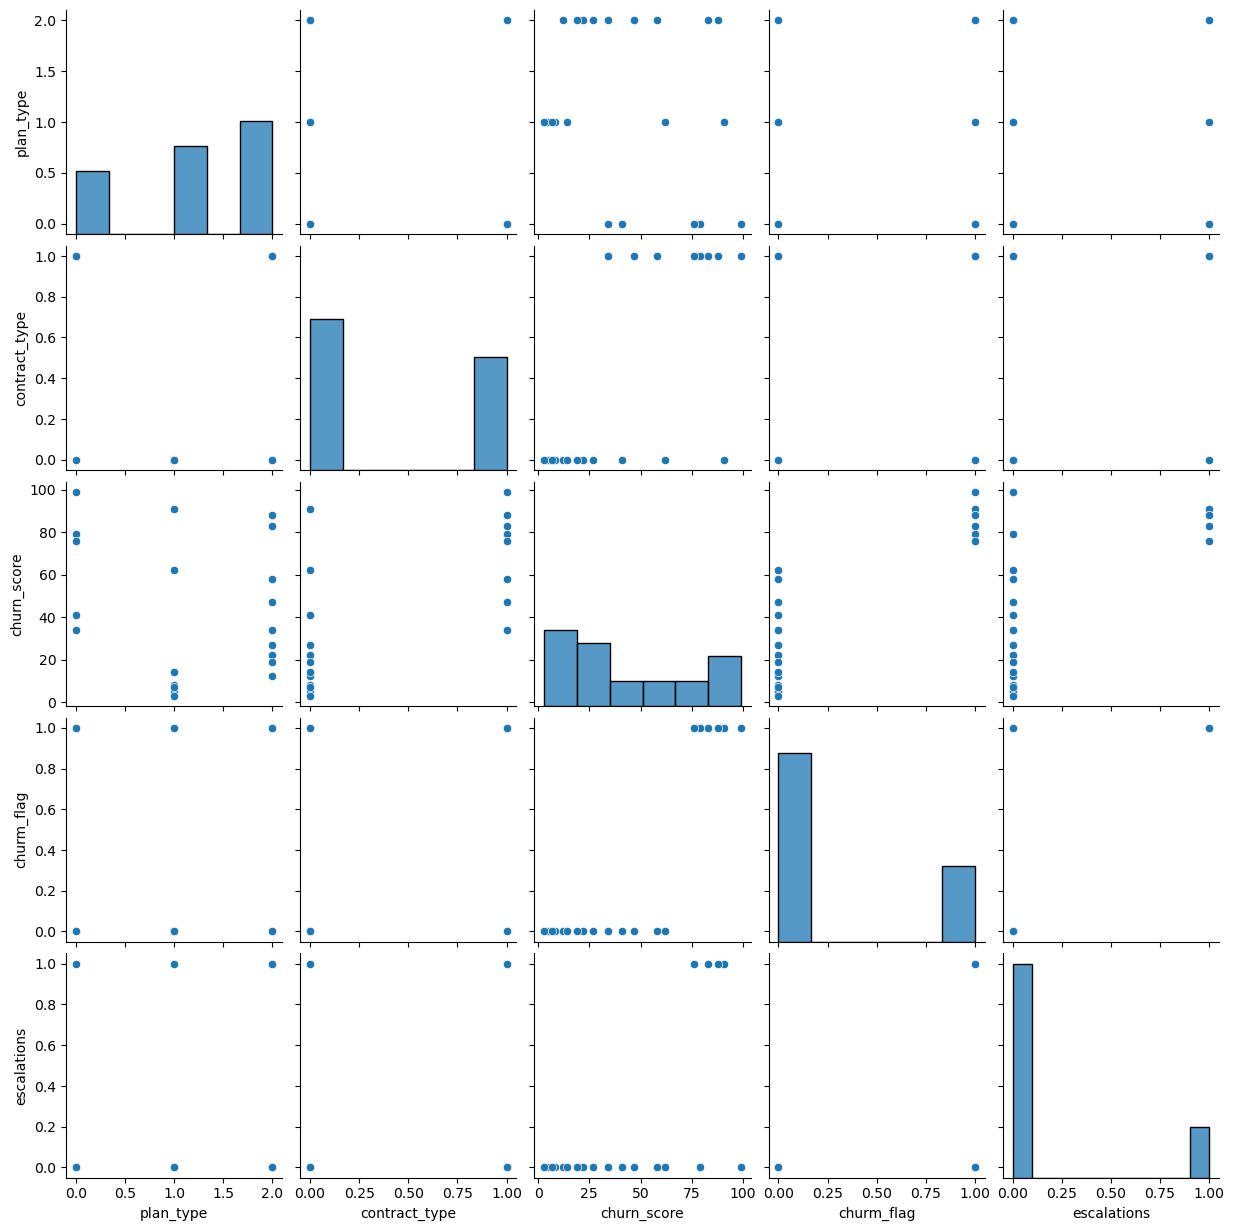

In [147]:
sns.pairplot(df_encod)

In [149]:
pd.pivot_table(
    df_n,
    values='churm_flag',
    index='',
    aggfunc='mean'
)

,churm_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [154]:
pd.pivot_table(
    df_n,
    index='plan_type',
    values=['monthly_charges','customerid','churm_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churm_flag' : 'mean'
    }
)

,churm_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [151]:
df_n.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churm_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days'],
      dtype='object')

In [161]:
# wrking with sql in python (pandas)
conn = sqlite3.connect("text_database.sqlite")

# table detiles 
conn.execute('create table user(first_name TEXT,country TEXT, budget intger)')
# commit and save 
conn.commit()

OperationalError: table user already exists

In [160]:
# insert data
couror = conn.cursor()
couror.execute (
    """ 
        insert into user values 
            ('naveen','india',5000),
            ('rohit','pakishathan',3400),
            ('vinod','pune',5490)
    
    """
)
conn.commit()
print("data insert sucessfully")

data insert sucessfully


In [164]:
# check inserted data in table 
conn = sqlite3.connect("text_database.sqlite")
query = """ select * from user """

df_ruselt = pd.read_sql(query,conn)
df_ruselt.head()

,first_name,country,budget
0,naveen,india,5000
1,rohit,pakishathan,3400
2,vinod,pune,5490
